# Diabetic Retinopathy using EfficientNet

## 1. Import Library

In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt
# 1. IMPORT TẤT CẢ KIẾN TRÚC EFFICIENTNET TỪ B0 ĐẾN B4
from tensorflow.keras.applications import (
    EfficientNetB0, 
    EfficientNetB1, 
    EfficientNetB2, 
    EfficientNetB3, 
    EfficientNetB4
)
# Hàm tiền xử lý dùng chung cho toàn bộ họ EfficientNet
from tensorflow.keras.applications.efficientnet import preprocess_input as preprocess_effnet

I0000 00:00:1785053773.023276   30910 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785053775.800273   30910 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1785053807.610413   30910 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
MODEL_VERSION = ["B0", "B1", "B2", "B3", "B4"]
EFFNET_DICT = {
    "B0": EfficientNetB0,
    "B1": EfficientNetB1,
    "B2": EfficientNetB2,
    "B3": EfficientNetB3,
    "B4": EfficientNetB4
}

In [3]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [4]:
BATCH_SIZE=4

In [5]:
with open("../../../data/processed/aptos/sample_200/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [6]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [7]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 763 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [9]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [10]:
def preprocess_function_effnet(image, label): 
    image = tf.cast(image, tf.float32)
    image = preprocess_effnet(image)
    return image, label

### Xử lí data trước khi train 

In [11]:
# 3. KHỞI TẠO TẬP DATASET TRAIN
with tf.device('/CPU:0'):
    train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    # Áp dụng hàm tiền xử lý (map) và cho phép CPU tự động tối ưu luồng (AUTOTUNE)
    train_dataset = train_dataset.map(preprocess_function_effnet, num_parallel_calls=tf.data.AUTOTUNE)
    # Chia lô (batch) và nạp sẵn dữ liệu cho vòng lặp kế tiếp (prefetch) để tăng tốc GPU
    train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test))
    test_dataset = test_dataset.map(preprocess_function_effnet, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    val_dataset = val_dataset.map(preprocess_function_effnet, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1785053837.376392   30910 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Ảnh tệp train

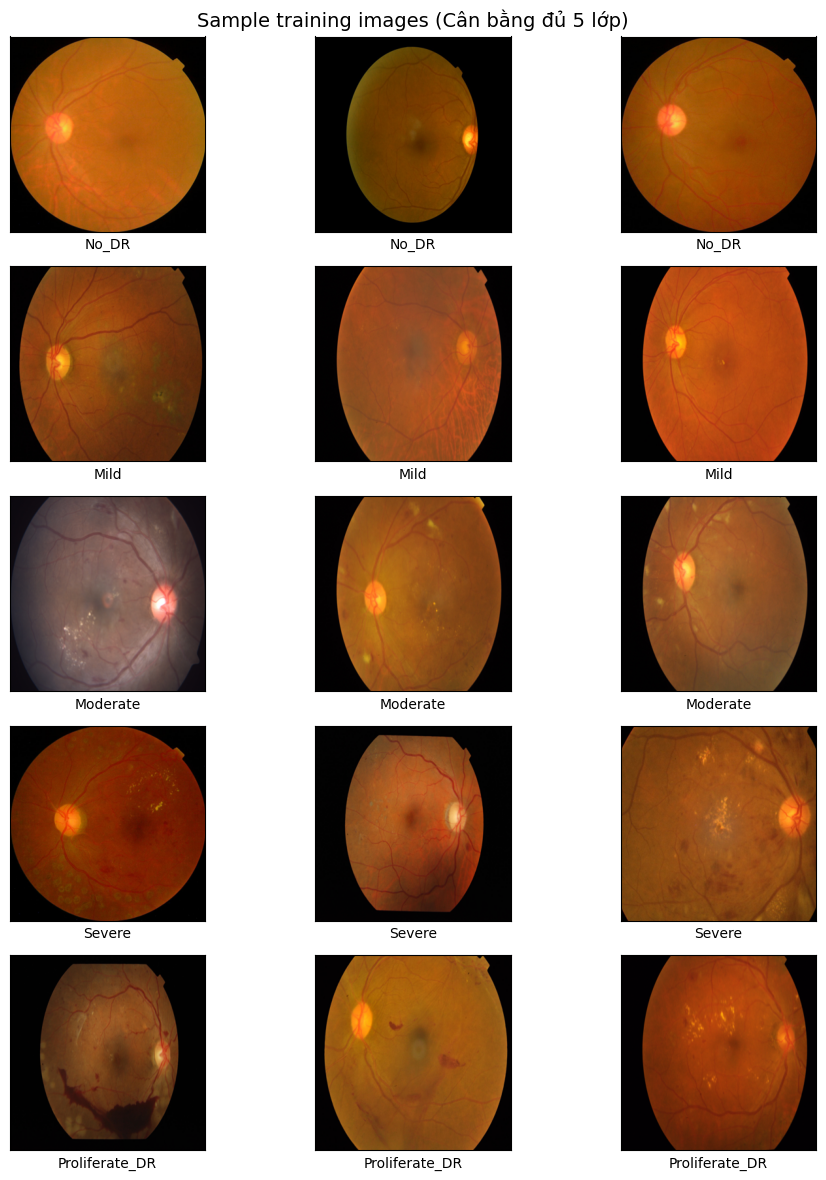

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

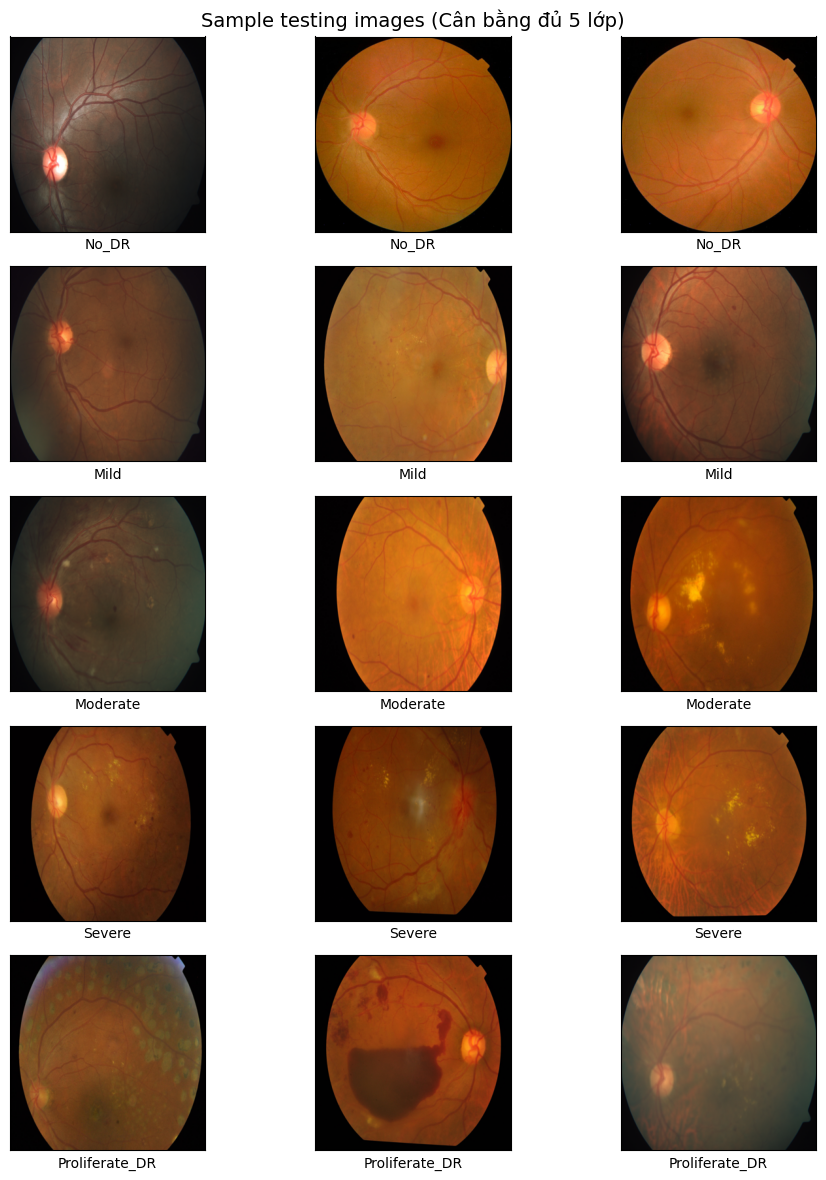

In [13]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng các model EfficientNet

In [14]:
def build_efficientnet_model(model_name, input_shape, num_classes):
    # Lấy class mô hình tương ứng từ từ điển
    BaseModelClass = EFFNET_DICT[model_name]
    
    print(f"🚀 Đang khởi tạo kiến trúc: EfficientNet{model_name}...")
    
    # Khởi tạo Base Model
    base_model = BaseModelClass(weights='imagenet', 
                                include_top=False, 
                                input_shape=input_shape)
    
    # Đóng băng (Freeze) phần thân
    base_model.trainable = False
    
    # Xây dựng Classification Head
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.4)(x) 
    
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions, name=f"Efficient{model_name}_APTOS_200")
    
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

### 4.1 Xây dựng model EfficientNetB0

In [15]:
model_efficientb0 = build_efficientnet_model("B0", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb0.summary()

🚀 Đang khởi tạo kiến trúc: EfficientNetB0...


Model: "EfficientB0_APTOS_200"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 300, 300,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 300, 300,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 300, 300,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │        512 │ block1a_se_excit

 Total params: 4,383,912 (16.72 MB)

 Trainable params: 331,781 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

### 4.2 Xây dựng model EfficientNetB1

In [16]:
model_efficientb1 = build_efficientnet_model("B1", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb1.summary()

🚀 Đang khởi tạo kiến trúc: EfficientNetB1...


Model: "EfficientB1_APTOS_200"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 300, 300,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 300, 300,  │          7 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 300, 300,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_3[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │        512 │ block1a_se_excit

 Total params: 6,909,580 (26.36 MB)

 Trainable params: 331,781 (1.27 MB)

 Non-trainable params: 6,577,799 (25.09 MB)

### 4.3 Xây dựng model EfficientB2

In [17]:
model_efficientb2 = build_efficientnet_model("B2", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb2.summary()

🚀 Đang khởi tạo kiến trúc: EfficientNetB2...


Model: "EfficientB2_APTOS_200"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_4         │ (None, 300, 300,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_2     │ (None, 300, 300,  │          7 │ rescaling_4[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_5         │ (None, 300, 300,  │          0 │ normalization_2[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_5[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │        512 │ block1a_se_excit

 Total params: 8,136,190 (31.04 MB)

 Trainable params: 364,805 (1.39 MB)

 Non-trainable params: 7,771,385 (29.65 MB)

### 4.4 Xây dựng model EfficientB3

In [18]:
model_efficientb3 = build_efficientnet_model("B3", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb3.summary()

🚀 Đang khởi tạo kiến trúc: EfficientNetB3...


Model: "EfficientB3_APTOS_200"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_6         │ (None, 300, 300,  │          0 │ input_layer_3[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_3     │ (None, 300, 300,  │          7 │ rescaling_6[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_7         │ (None, 300, 300,  │          0 │ normalization_3[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_7[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │        960 │ block1a_se_excit

 Total params: 11,184,436 (42.67 MB)

 Trainable params: 397,829 (1.52 MB)

 Non-trainable params: 10,786,607 (41.15 MB)

### 4.5 Xây dựng model EfficientB4

In [19]:
model_efficientb4 = build_efficientnet_model("B4", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb4.summary()

🚀 Đang khởi tạo kiến trúc: EfficientNetB4...


Model: "EfficientB4_APTOS_200"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_8         │ (None, 300, 300,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_4     │ (None, 300, 300,  │          7 │ rescaling_8[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_9         │ (None, 300, 300,  │          0 │ normalization_4[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_9[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │      1,296 │ stem_conv_pad[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        192 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        432 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        192 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 48)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 48)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 12)  │        588 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 48)  │        624 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 48)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │      1,152 │ block1a_se_excit

 Total params: 18,141,284 (69.20 MB)

 Trainable params: 463,877 (1.77 MB)

 Non-trainable params: 17,677,407 (67.43 MB)

## 5. Compile & Train 

### 5.1 Compile & train EfficientNetB0

In [20]:
model_efficientb0.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb0_aptos_200_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb0 = model_efficientb0.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785053859.669740   31956 service.cc:153] XLA service 0x76f214069a50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785053859.669769   31956 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1785053860.034606   31956 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785053861.679796   31956 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1785053862.057888   31956 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_34877__.259
I0000 00:00:1785053879.929040   31956 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1785053888.287488   31956 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_34877__.259



Epoch 1: val_accuracy improved from None to 0.60209, saving model to ../../../data/models/efficientb0_aptos_200_best.keras

Epoch 1: finished saving model to ../../../data/models/efficientb0_aptos_200_best.keras
191/191 - 62s - 324ms/step - accuracy: 0.4404 - loss: 1.8907 - val_accuracy: 0.6021 - val_loss: 1.0763 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.60209 to 0.62827, saving model to ../../../data/models/efficientb0_aptos_200_best.keras

Epoch 2: finished saving model to ../../../data/models/efficientb0_aptos_200_best.keras
191/191 - 7s - 37ms/step - accuracy: 0.5334 - loss: 1.4457 - val_accuracy: 0.6283 - val_loss: 1.0320 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.62827
191/191 - 4s - 20ms/step - accuracy: 0.6750 - loss: 0.9388 - val_accuracy: 0.6126 - val_loss: 1.2673 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy did not improve from 0.62827
191/191 - 4s - 20ms/step - accuracy: 0.7261 - loss: 0.

### 5.2 Compile & train EfficientNetB1

In [21]:
model_efficientb1.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb1_aptos_200_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb1 = model_efficientb1.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785053986.258111   31957 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_78539__.361
I0000 00:00:1785054006.062598   31958 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_78539__.361



Epoch 1: val_accuracy improved from None to 0.63351, saving model to ../../../data/models/efficientb1_aptos_200_best.keras

Epoch 1: finished saving model to ../../../data/models/efficientb1_aptos_200_best.keras
191/191 - 60s - 313ms/step - accuracy: 0.4155 - loss: 1.9811 - val_accuracy: 0.6335 - val_loss: 0.9766 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.63351 to 0.64398, saving model to ../../../data/models/efficientb1_aptos_200_best.keras

Epoch 2: finished saving model to ../../../data/models/efficientb1_aptos_200_best.keras
191/191 - 6s - 31ms/step - accuracy: 0.5740 - loss: 1.3828 - val_accuracy: 0.6440 - val_loss: 1.0167 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.64398
191/191 - 5s - 26ms/step - accuracy: 0.6619 - loss: 1.0150 - val_accuracy: 0.6335 - val_loss: 1.0658 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy improved from 0.64398 to 0.65445, saving model to ../../../data/models/efficientb1_

### 5.3 Compile & train EfficientNetB2

In [22]:
model_efficientb2.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb2_aptos_200_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb2 = model_efficientb2.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785054120.964067   31958 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_123559__.361
I0000 00:00:1785054148.735211   31957 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_123559__.361



Epoch 1: val_accuracy improved from None to 0.51832, saving model to ../../../data/models/efficientb2_aptos_200_best.keras

Epoch 1: finished saving model to ../../../data/models/efficientb2_aptos_200_best.keras
191/191 - 73s - 380ms/step - accuracy: 0.4142 - loss: 2.2408 - val_accuracy: 0.5183 - val_loss: 1.1160 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.51832 to 0.59686, saving model to ../../../data/models/efficientb2_aptos_200_best.keras

Epoch 2: finished saving model to ../../../data/models/efficientb2_aptos_200_best.keras
191/191 - 7s - 36ms/step - accuracy: 0.5374 - loss: 1.6289 - val_accuracy: 0.5969 - val_loss: 1.0458 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.59686 to 0.64921, saving model to ../../../data/models/efficientb2_aptos_200_best.keras

Epoch 3: finished saving model to ../../../data/models/efficientb2_aptos_200_best.keras
191/191 - 6s - 33ms/step - accuracy: 0.6029 - loss: 1.1986 - val_accuracy: 0.64

### 5.4 Compile & train EfficientNetB3

In [23]:
model_efficientb3.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb3_aptos_200_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb3 = model_efficientb3.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785054278.189605   31958 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_172831__.406
I0000 00:00:1785054312.761398   31956 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_172831__.406



Epoch 1: val_accuracy improved from None to 0.56545, saving model to ../../../data/models/efficientb3_aptos_200_best.keras

Epoch 1: finished saving model to ../../../data/models/efficientb3_aptos_200_best.keras
191/191 - 92s - 479ms/step - accuracy: 0.4377 - loss: 2.3153 - val_accuracy: 0.5654 - val_loss: 0.9774 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.56545 to 0.61257, saving model to ../../../data/models/efficientb3_aptos_200_best.keras

Epoch 2: finished saving model to ../../../data/models/efficientb3_aptos_200_best.keras
191/191 - 8s - 44ms/step - accuracy: 0.5491 - loss: 1.6831 - val_accuracy: 0.6126 - val_loss: 1.1121 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.61257 to 0.63351, saving model to ../../../data/models/efficientb3_aptos_200_best.keras

Epoch 3: finished saving model to ../../../data/models/efficientb3_aptos_200_best.keras
191/191 - 8s - 42ms/step - accuracy: 0.5898 - loss: 1.3298 - val_accuracy: 0.63

### 5.5 Compile & train EfficientNetB4

In [24]:
model_efficientb4.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb4_aptos_200_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb4 = model_efficientb4.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785054470.497852   31959 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_229716__.496
I0000 00:00:1785054505.283620   31955 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_229716__.496



Epoch 1: val_accuracy improved from None to 0.50262, saving model to ../../../data/models/efficientb4_aptos_200_best.keras

Epoch 1: finished saving model to ../../../data/models/efficientb4_aptos_200_best.keras
191/191 - 97s - 510ms/step - accuracy: 0.4089 - loss: 2.6403 - val_accuracy: 0.5026 - val_loss: 1.1381 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.50262 to 0.57068, saving model to ../../../data/models/efficientb4_aptos_200_best.keras

Epoch 2: finished saving model to ../../../data/models/efficientb4_aptos_200_best.keras
191/191 - 11s - 58ms/step - accuracy: 0.5518 - loss: 1.7655 - val_accuracy: 0.5707 - val_loss: 1.1440 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.57068 to 0.59686, saving model to ../../../data/models/efficientb4_aptos_200_best.keras

Epoch 3: finished saving model to ../../../data/models/efficientb4_aptos_200_best.keras
191/191 - 11s - 56ms/step - accuracy: 0.5885 - loss: 1.4379 - val_accuracy: 0.

## 6. Visualize Training

### 6.1 Visualize Training EfficientNetB0

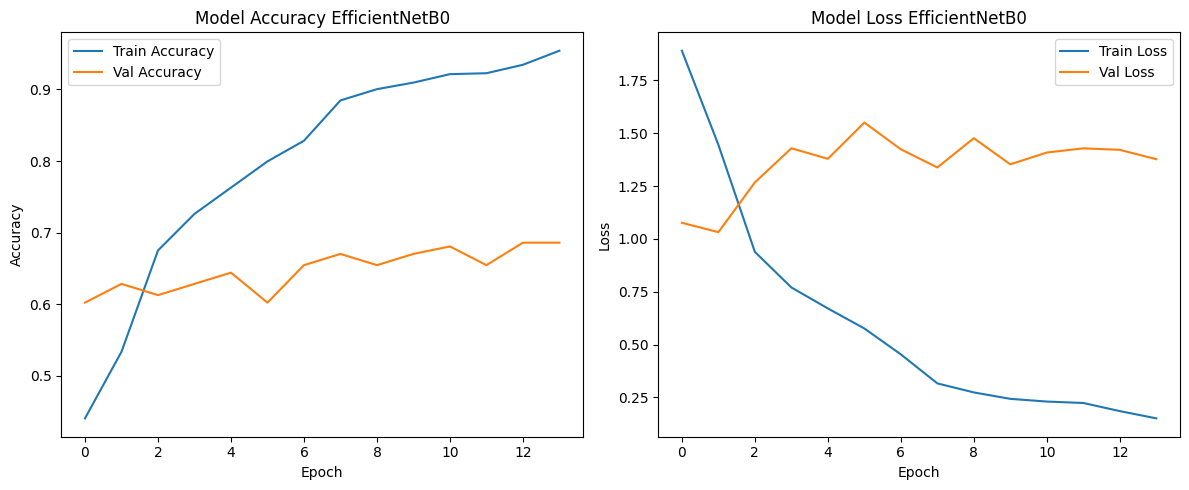

In [25]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb0.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb0.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB0')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb0.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb0.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB0')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.2 Visualize Training EfficientNetB1

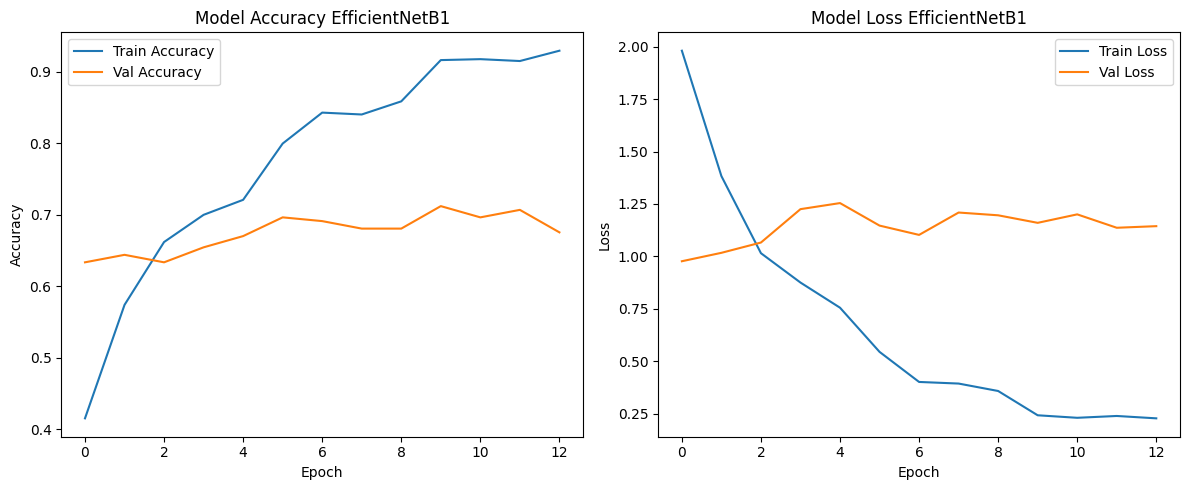

In [26]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb1.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb1.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB1')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb1.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb1.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB1')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training EfficientNetB2

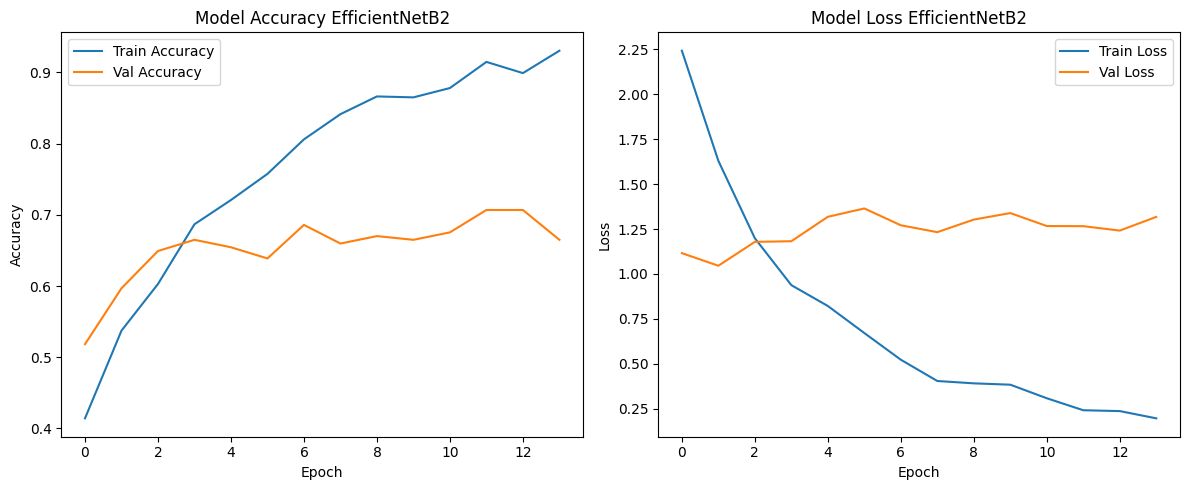

In [27]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb2.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb2.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB2')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb2.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb2.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB2')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training EfficientNetB3

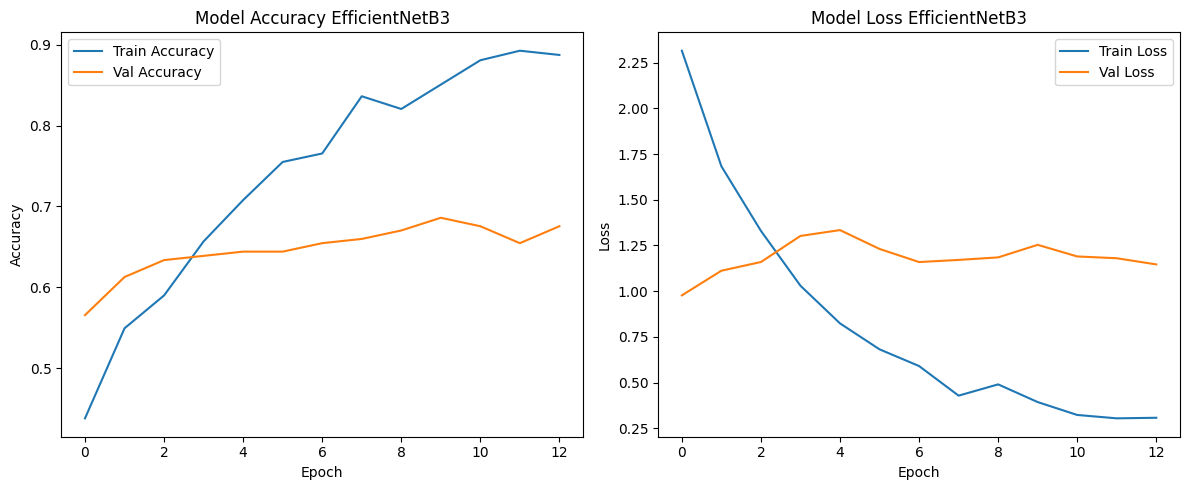

In [28]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb3.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb3.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB3')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb3.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb3.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB3')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training EfficientNetB4

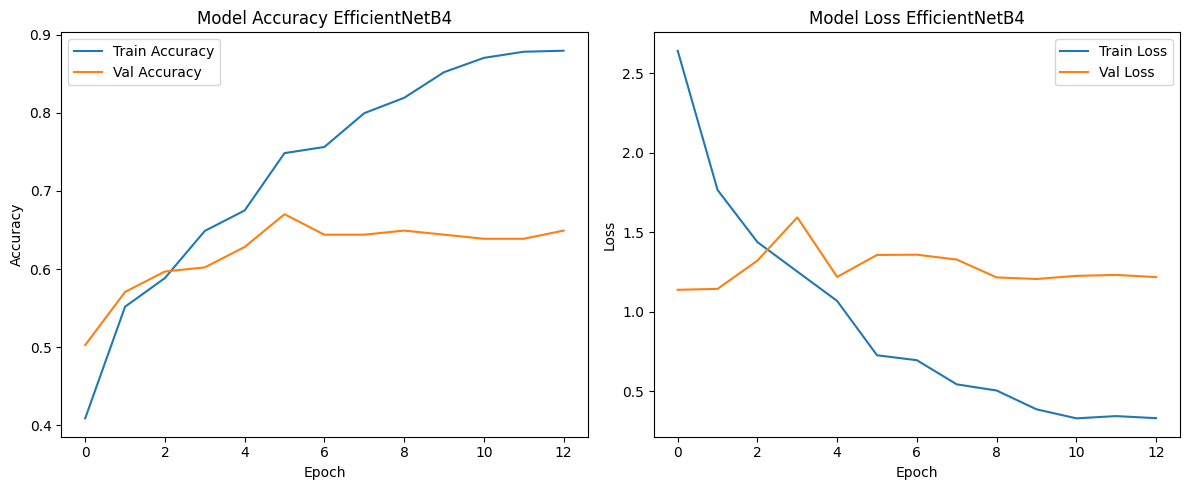

In [29]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb4.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb4.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB4')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb4.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb4.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB4')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7.Evualte on test set

In [30]:
test_loss_efficientb0, test_acc_effcientb0 = model_efficientb0.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB0: {test_loss_efficientb0:.4f}')
print(f'Test Accuracy EfficientNetB0: {test_acc_effcientb0:.4f}') 

Test Loss EfficientNetB0: 0.8081
Test Accuracy EfficientNetB0: 0.6913


In [31]:
test_loss_efficientb1, test_acc_effcientb1 = model_efficientb1.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB1: {test_loss_efficientb1:.4f}')
print(f'Test Accuracy EfficientNetB1: {test_acc_effcientb1:.4f}') 

Test Loss EfficientNetB1: 0.8160
Test Accuracy EfficientNetB1: 0.6803


In [32]:
test_loss_efficientb2, test_acc_effcientb2 = model_efficientb2.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB2: {test_loss_efficientb2:.4f}')
print(f'Test Accuracy EfficientNetB2: {test_acc_effcientb2:.4f}') 

Test Loss EfficientNetB2: 0.9415
Test Accuracy EfficientNetB2: 0.6421


In [33]:
test_loss_efficientb3, test_acc_effcientb3 = model_efficientb3.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB3: {test_loss_efficientb3:.4f}')
print(f'Test Accuracy EfficientNetB3: {test_acc_effcientb3:.4f}') 

Test Loss EfficientNetB3: 0.8993
Test Accuracy EfficientNetB3: 0.6011


In [34]:
test_loss_efficientb4, test_acc_effcientb4 = model_efficientb4.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB4: {test_loss_efficientb4:.4f}')
print(f'Test Accuracy EfficientNetB4: {test_acc_effcientb4:.4f}') 

Test Loss EfficientNetB4: 1.1004
Test Accuracy EfficientNetB4: 0.4617
